# CIFAR-10 Image Classification: what do convolutions actually buy you?

**The question:** CIFAR-10 is 60,000 tiny colour photos (32 x 32 pixels) of ten everyday things: planes, cars, birds, cats, deer, dogs, frogs, horses, ships and trucks. A neural network that looks at the pixels and names the object is the "hello world" of computer vision. But *why* are convolutional networks (CNNs) so much better at this than simpler models? How much of the gain comes from the architecture, and how much from tricks like data augmentation? And where do even good models still go wrong?

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data
4. Hypotheses and why we chose each test
5. H1: does colour alone say something about the class?
6. The model ladder (four rungs)
7. H2 to H4: is each step really better? (McNemar tests)
8. H5: where do the mistakes go?
9. Takeaways
10. Limitations

**Run it:** `uv run jupyter lab DL/cifar10-cnn/cifar10_cnn.ipynb`, or *Run All* in any Jupyter. CIFAR-10 (about 170 MB) downloads itself on the first run. It uses a GPU if one is present and takes about 10 minutes on one.

## 1. 💡 The simple analogy

Imagine telling a cat from a dog by looking at a tiny photo through a **magnifying glass that you slide across the picture**.

- A **simple model** (logistic regression, or an MLP) is like reading a *list of 3,072 numbers* (every pixel's colour) with no idea which numbers sit next to which. It has to learn "the pixel in the top-left means cat" separately for every position, so a cat shifted two pixels to the right looks like a completely different picture.
- A **convolutional network** slides the *same small magnifying glass* (a **filter**, a 3 x 3 patch of weights) over the whole image, looking for the same pattern everywhere: an edge, a corner, a patch of fur. Early layers find edges, later layers combine edges into ears and wheels, and the last layers combine those into "cat" or "truck". Because the same filter is reused everywhere, the network needs far fewer weights **and** doesn't care exactly where in the picture something is.
- **Data augmentation** is like showing the learner *the same photo flipped and nudged*: a horse is still a horse if it faces left, so we teach the network that for free.

The rest of the notebook measures how much each idea helps, with proper statistics.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed, number of epochs and batch size keeps the notebook reproducible and avoids "magic numbers". With the seeds fixed (and the GPU set to deterministic mode), every model comes out the same each time you run it.

In [1]:
import contextlib
import io
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from torch import nn
from torchvision import datasets

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 42
N_SEEDS = 3
EPOCHS = 20
BATCH_SIZE = 256
N_BOOTSTRAP = 5_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASSES = ["plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU
torch.backends.cudnn.benchmark = False
sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Audit the data first

*What:* load CIFAR-10 and check what we have. *Why:* before training anything we should know the shape of the data, whether the classes are balanced, and what a random guess would score.

> **Problems in the legacy notebook this replaces:** it used `examples.next()` (an iterator method that no longer exists in current PyTorch), showed each image through **only its red channel in black-and-white** (`samples[i][0]` with `cmap="binary"`, which is not what the network sees), trained a tiny LeNet for 80 epochs with batches of 8 (slow and noisy), compared against nothing and reported a single accuracy number from one run.

In [2]:
def load_cifar10() -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads CIFAR-10 into memory as float tensors in [0, 1], channels first.

    Returns:
        Training images and labels, then test images and labels (images on the CPU).

    Raises:
        ValueError: If the dataset does not have the expected shape.
    """
    with contextlib.redirect_stderr(io.StringIO()):  # hide the download progress bar
        train = datasets.CIFAR10(DATA_DIR, train=True, download=True)
        test = datasets.CIFAR10(DATA_DIR, train=False, download=True)

    def to_tensor(images: np.ndarray) -> torch.Tensor:
        return torch.from_numpy(images).permute(0, 3, 1, 2).float() / 255

    if train.data.shape != (50_000, 32, 32, 3) or test.data.shape != (10_000, 32, 32, 3):
        raise ValueError("Unexpected CIFAR-10 shape")
    return (
        to_tensor(train.data),
        torch.tensor(train.targets),
        to_tensor(test.data),
        torch.tensor(test.targets),
    )


raw_train_x, train_y, raw_test_x, test_y = load_cifar10()
print(f"Training images: {tuple(raw_train_x.shape)}   Test images: {tuple(raw_test_x.shape)}")
counts = pd.Series(train_y.numpy()).value_counts().sort_index()
counts.index = CLASSES
print("Images per class in the training set:", counts.unique().tolist(), "(perfectly balanced)")
print(
    f"Pixel range: {raw_train_x.min():.0f} to {raw_train_x.max():.0f}; "
    f"mean colour (R, G, B): {[round(float(m), 3) for m in raw_train_x.mean(dim=(0, 2, 3))]}"
)
print(
    f"Majority-class accuracy (the bar for a model that learned nothing): "
    f"{counts.max() / counts.sum():.0%}"
)

Training images: (50000, 3, 32, 32)   Test images: (10000, 3, 32, 32)
Images per class in the training set: [5000] (perfectly balanced)
Pixel range: 0 to 1; mean colour (R, G, B): [0.491, 0.482, 0.447]
Majority-class accuracy (the bar for a model that learned nothing): 10%


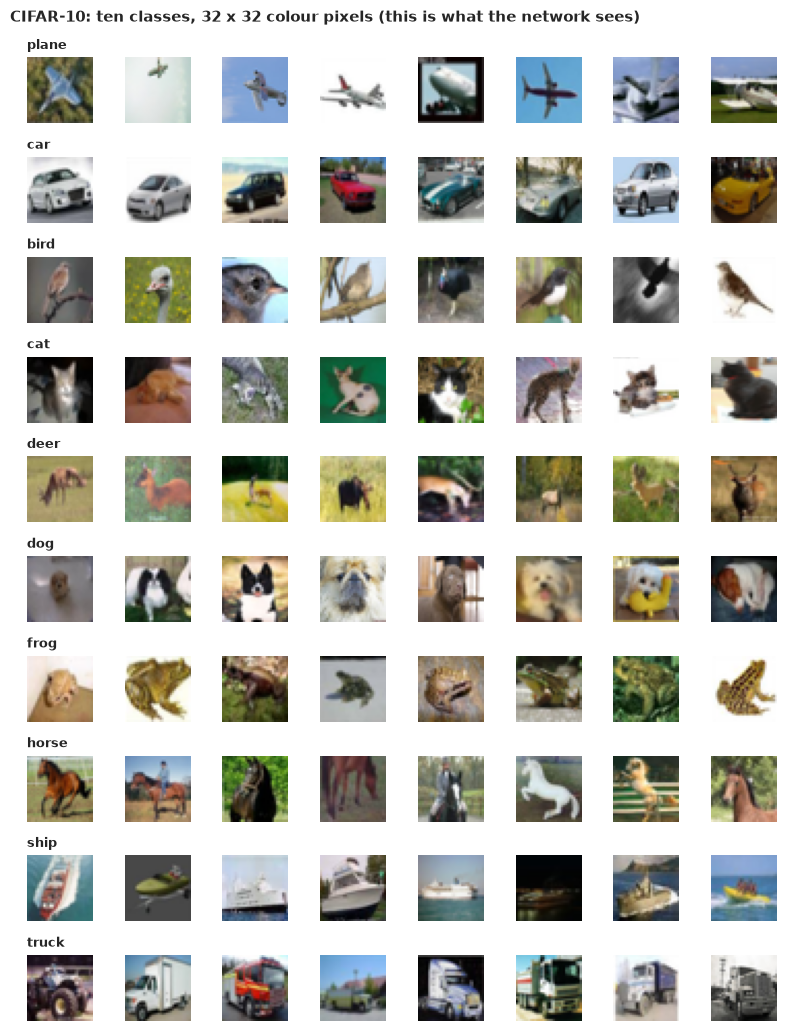

In [3]:
fig, axes = plt.subplots(10, 8, figsize=(8, 10.5))
rng = np.random.default_rng(SEED)
for row, name in enumerate(CLASSES):
    indices = rng.choice(np.where(train_y.numpy() == row)[0], 8, replace=False)
    for col, index in enumerate(indices):
        axes[row, col].imshow(raw_train_x[index].permute(1, 2, 0).numpy())
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(name, loc="left", fontsize=9, fontweight="bold")
fig.suptitle(
    "CIFAR-10: ten classes, 32 x 32 colour pixels (this is what the network sees)",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_samples.png", dpi=130)
plt.show()

**How to read this.** There are **50,000 training images and 10,000 test images**, each 32 x 32 pixels with 3 colour channels, **perfectly balanced at 5,000 per class** in training (1,000 per class in the test set). So a model that learned nothing and always guessed one class would score **10%**: that's the bar.

The mosaic shows what the network actually sees: very small, blurry, noisy photos. Notice how hard some are even for a person (the bird that looks like a dog, the deer in the bushes). We should not expect 100%.

## 4. 🔬 Hypotheses and why we chose each test

Here are the questions, each with its null (H₀, "nothing special") and alternative (Hₐ), written **before** looking at any results:

| # | Question | H₀ | Hₐ | Method |
|---|---|---|---|---|
| H1 | Does a simple colour summary differ between classes? | Same distribution in all 10 classes | At least one class differs | Kruskal-Wallis with effect size ε² |
| H2 | Does a CNN beat a fully connected network (MLP)? | Same accuracy | Different | Exact McNemar test on the same 10,000 test images; bootstrap CI |
| H3 | Does a modern CNN beat the legacy LeNet? | Same accuracy | Different | McNemar test |
| H4 | Does data augmentation help? | Same accuracy | Augmentation is better | McNemar test; train-test gap |
| H5 | Is accuracy the same for every class? | Same accuracy in all classes | Some classes are harder | Chi-square test, Cramér's V, Wilson CIs |

**Why Kruskal-Wallis?** It is the rank-based version of one-way ANOVA: it compares the ten classes without assuming bell-shaped data. Its effect size **ε²** is about 0.01 small, 0.06 medium, 0.14 large.

**Why McNemar's test for comparing two models?** Two classifiers are tested on the **same 10,000 images**, so the right comparison is *paired*. Only the images where **exactly one** of the two models is right carry any information (if both are right or both are wrong, they tie). McNemar's test asks: among those disagreements, is each model equally likely to be the one that is right? **H₀: yes.** We use the **exact** version (a binomial test on the disagreement counts), and add a **bootstrap 95% CI** for the accuracy difference by re-drawing the test images with replacement 5,000 times. **Why not just compare the average accuracies from three training seeds?** With three seeds, a paired test can't get a small p-value, and seed averages hide whether the gap is real on the test images themselves. We *report* the seed spread too, but McNemar is the sharper tool.

## 5. H1: does colour alone say something about the class?

*What:* before any neural network, a quick sanity check. For each training image we compute one very crude summary: its **average blue minus average red**. If this simple number already differs between classes, then even a model that ignores shape should beat random guessing. We test **H₀: the ten classes have the same distribution of this summary** with Kruskal-Wallis.

Kruskal-Wallis: H = 14684, p = 0.0e+00, epsilon^2 = 0.29
Median 'blueness' (blue minus red, 0 to 255 scale), most red to most blue:
frog    -29.400000
deer    -22.900000
horse   -20.400000
dog     -18.700001
bird    -16.900000
cat     -16.799999
truck    -3.400000
car      -2.500000
plane     9.100000
ship     13.000000


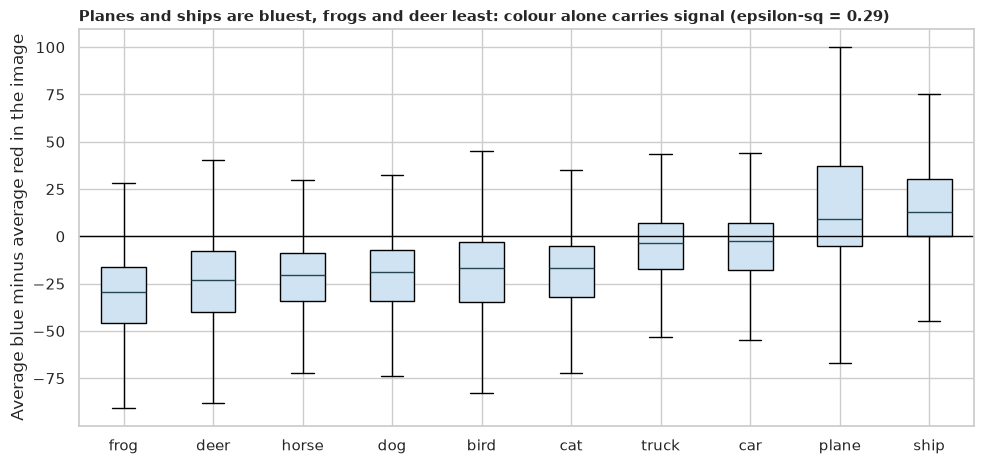

In [4]:
mean_colour = raw_train_x.mean(dim=(2, 3)).numpy() * 255  # average R, G, B per image
blueness = mean_colour[:, 2] - mean_colour[:, 0]  # blue minus red: positive = bluer
labels = train_y.numpy()
groups = [blueness[labels == k] for k in range(10)]
h_stat, p_kw = stats.kruskal(*groups)
epsilon_sq = (h_stat - 10 + 1) / (len(labels) - 10)
medians = pd.Series([np.median(g) for g in groups], index=CLASSES).sort_values()
plane, ship, frog = (np.median(groups[CLASSES.index(c)]) for c in ("plane", "ship", "frog"))
print(f"Kruskal-Wallis: H = {h_stat:.0f}, p = {fmt_p(p_kw)}, epsilon^2 = {epsilon_sq:.2f}")
print("Median 'blueness' (blue minus red, 0 to 255 scale), most red to most blue:")
print(medians.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 4.8))
order = list(medians.index)
ax.boxplot(
    [blueness[labels == CLASSES.index(c)] for c in order],
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#cfe3f2"},
    medianprops={"color": NAVY},
)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(range(1, 11), order)
ax.set_ylabel("Average blue minus average red in the image")
ax.set_title(
    f"Planes and ships are bluest, frogs and deer least: colour alone carries signal "
    f"(epsilon-sq = {epsilon_sq:.2f})",
    loc="left",
    fontweight="bold",
    fontsize=10.5,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_blueness_by_class.png", dpi=150)
plt.show()

**How to read this.** The Kruskal-Wallis test gives H ≈ 14,700 and p ≈ 0, with an effect size of **ε² ≈ 0.29, a large effect** (the "large" threshold is 0.14), so **we reject H₀: colour alone separates the classes to a surprising degree.** The box plot makes it concrete: **ships (median +13) and planes (+9)**, with their sea and sky, are the bluest; **cars and trucks** sit near neutral (−3 to −2); and **frogs (−29), deer (−23), horses (−20), dogs, birds and cats** are the reddest (green, brown and tan backgrounds). So even a model that only counted colours would beat the 10% guessing baseline, and a good network, we should hope, learns *much* more than colour (otherwise it would call every frog photographed on blue water a ship).

## 6. The model ladder (four rungs)

*What:* four models of increasing sophistication, all trained with the **same recipe** so differences come from the *model*, not the training:

1. **Logistic regression:** one layer that turns the 3,072 pixel values straight into 10 class scores. No hidden layers; the linear baseline.
2. **MLP** (multi-layer perceptron): a fully connected network (3,072 → 512 → 256 → 10). It can learn non-linear patterns but treats every pixel position independently.
3. **LeNet:** the small CNN from the legacy notebook (two convolutional layers with 6 and 16 filters, about 62,000 weights).
4. **Modern CNN:** three blocks of *two* 3 x 3 convolutions each (32, 64 and 128 filters) with **batch normalisation** (which keeps each layer's numbers in a healthy range so training is stable) and max-pooling, then **global average pooling** and one linear layer.

Plus a fifth entry: the **Modern CNN trained with data augmentation** (random left-right flips and shifts of up to 4 pixels, applied afresh to every image every epoch).

**The shared recipe:** the AdamW optimiser with a "one-cycle" learning-rate schedule (the rate rises then falls over training), 20 epochs, batches of 256, with the 50,000 images on the GPU. **How we avoid cheating:** the test images are never used for training, tuning or choosing the epoch: we report the accuracy **after the final epoch**, not the best epoch (picking the best epoch on the test set would be a leak). Each model is trained from **3 different seeds** to show how much the result wobbles.

In [5]:
MEAN = raw_train_x.mean(dim=(0, 2, 3), keepdim=True)
STD = raw_train_x.std(dim=(0, 2, 3), keepdim=True)
train_x = ((raw_train_x - MEAN) / STD).to(DEVICE)
test_x = ((raw_test_x - MEAN) / STD).to(DEVICE)
train_labels, test_labels = train_y.to(DEVICE), test_y.to(DEVICE)


def augment(batch: torch.Tensor, generator: torch.Generator) -> torch.Tensor:
    """Randomly flips each image left-right and shifts it by up to 4 pixels.

    Each image gets its own flip and shift, so the network never sees exactly the same
    picture twice. Done on the GPU with an affine grid; shifts are whole pixels.

    Args:
        batch: Images of shape (N, 3, 32, 32).
        generator: Random generator on the same device, for reproducibility.

    Returns:
        The augmented batch.
    """
    n = len(batch)
    flip = (torch.randint(0, 2, (n,), device=batch.device, generator=generator) * 2 - 1).float()
    shift = torch.randint(-4, 5, (n, 2), device=batch.device, generator=generator).float() / 16
    theta = torch.zeros(n, 2, 3, device=batch.device)
    theta[:, 0, 0], theta[:, 1, 1] = flip, 1.0
    theta[:, :, 2] = shift
    grid = F.affine_grid(theta, list(batch.shape), align_corners=False)
    return F.grid_sample(batch, grid, padding_mode="reflection", align_corners=False)


def conv_block(c_in: int, c_out: int) -> nn.Sequential:
    """Two 3x3 convolutions with batch norm and ReLU, then 2x2 max pooling.

    Args:
        c_in: Input channels.
        c_out: Output channels.

    Returns:
        The block as a sequential module.
    """
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


def build_model(name: str) -> nn.Module:
    """Builds one rung of the model ladder.

    Args:
        name: ``"Logistic regression"``, ``"MLP"``, ``"LeNet"`` or ``"Modern CNN"``.

    Returns:
        The untrained model on the active device.
    """
    if name == "Logistic regression":
        model = nn.Sequential(nn.Flatten(), nn.Linear(3072, 10))
    elif name == "MLP":
        model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10),
        )
    elif name == "LeNet":  # the legacy notebook's network
        model = nn.Sequential(
            nn.Conv2d(3, 6, 5),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(6, 16, 5),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(400, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, 10),
        )
    else:
        model = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128, 10),
        )
    return model.to(DEVICE)


MODEL_NAMES = ["Logistic regression", "MLP", "LeNet", "Modern CNN"]
param_counts = {n: sum(p.numel() for p in build_model(n).parameters()) for n in MODEL_NAMES}
print({name: f"{count:,}" for name, count in param_counts.items()})

{'Logistic regression': '30,730', 'MLP': '1,707,274', 'LeNet': '62,006', 'Modern CNN': '288,746'}


In [6]:
def train_model(name: str, seed: int, augmented: bool) -> dict:
    """Trains one model and records its accuracy after every epoch.

    All models use the same recipe: AdamW with a one-cycle learning-rate schedule, 20 epochs,
    batches of 256. The seed fixes the starting weights, batch order and augmentation.

    Args:
        name: Model name from :data:`MODEL_NAMES`.
        seed: Seed for initialisation, batch order and augmentation.
        augmented: Whether to flip and shift the training images.

    Returns:
        Dictionary with per-epoch train and test accuracy, and the final test predictions
        and confidence (softmax probabilities).
    """
    torch.manual_seed(seed)
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    model = build_model(name)
    steps_per_epoch = (len(train_x) + BATCH_SIZE - 1) // BATCH_SIZE
    optimiser = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=5e-4)
    schedule = torch.optim.lr_scheduler.OneCycleLR(
        optimiser, max_lr=4e-3, total_steps=EPOCHS * steps_per_epoch
    )
    history = {"train": [], "test": []}
    for _ in range(EPOCHS):
        model.train()
        order = torch.randperm(len(train_x), device=DEVICE, generator=generator)
        correct = 0
        for start in range(0, len(train_x), BATCH_SIZE):
            batch = order[start : start + BATCH_SIZE]
            images = augment(train_x[batch], generator) if augmented else train_x[batch]
            logits = model(images)
            loss = F.cross_entropy(logits, train_labels[batch])
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()
            schedule.step()
            correct += int((logits.argmax(1) == train_labels[batch]).sum())
        model.eval()
        with torch.no_grad():
            test_logits = torch.cat(
                [model(test_x[i : i + 1000]) for i in range(0, len(test_x), 1000)]
            )
        history["train"].append(correct / len(train_x))
        history["test"].append(float((test_logits.argmax(1) == test_labels).float().mean()))
    probabilities = test_logits.softmax(1).cpu().numpy()
    return {
        "history": history,
        "probabilities": probabilities,
        "predictions": probabilities.argmax(1),
    }

Now train every model with 3 seeds each (this cell takes several minutes; a progress line prints as each model finishes).

In [7]:
RUNS = [(name, False) for name in MODEL_NAMES] + [("Modern CNN", True)]
results = {}
for name, augmented in RUNS:
    label = f"{name} + augmentation" if augmented else name
    start = time.time()
    results[label] = [train_model(name, 100 + seed, augmented) for seed in range(N_SEEDS)]
    final = [r["history"]["test"][-1] for r in results[label]]
    print(
        f"{label:28s} test accuracy {np.mean(final):.4f} (seeds: "
        f"{', '.join(f'{a:.3f}' for a in final)})  [{time.time() - start:.0f}s]"
    )

Logistic regression          test accuracy 0.3964 (seeds: 0.397, 0.395, 0.397)  [14s]


MLP                          test accuracy 0.5526 (seeds: 0.550, 0.553, 0.555)  [20s]


LeNet                        test accuracy 0.6589 (seeds: 0.656, 0.662, 0.659)  [36s]


Modern CNN                   test accuracy 0.8589 (seeds: 0.857, 0.860, 0.859)  [224s]


Modern CNN + augmentation    test accuracy 0.8894 (seeds: 0.893, 0.891, 0.884)  [231s]


**How to read this.** After 20 epochs each model's test accuracy is very stable across seeds (all within about half a percentage point), so the differences between rungs are far larger than seed-to-seed wobble: **logistic regression about 39.6%, MLP about 55.3%, LeNet about 65.9%, the modern CNN about 85.9%, and the modern CNN with augmentation about 88.9%.** (A guess would score 10%.)

Look at the parameter counts in the table below, because they hold the first big lesson: the **MLP has 1.7 million weights, 27 times more than LeNet's 62,000, yet is about 10 points *less* accurate.** More weights are not the point. *Where* the weights are shared is. Convolutional layers reuse the same small filters across the whole image, which builds in the idea "an ear is an ear wherever it appears".

In [8]:
LABELS = list(results)
truth = test_labels.cpu().numpy()
correct = {label: results[label][0]["predictions"] == truth for label in LABELS}  # seed 0

rows = {}
for label in LABELS:
    finals = np.array([r["history"]["test"][-1] for r in results[label]])
    half = stats.t.ppf(0.975, len(finals) - 1) * finals.std(ddof=1) / np.sqrt(len(finals))
    rows[label] = {
        "parameters": param_counts[label.split(" + ")[0]],
        "test accuracy": finals.mean(),
        "ci_low": finals.mean() - half,
        "ci_high": finals.mean() + half,
        "final train accuracy": np.mean([r["history"]["train"][-1] for r in results[label]]),
    }
ladder = pd.DataFrame(rows).T
ladder["generalisation gap"] = ladder["final train accuracy"] - ladder["test accuracy"]
ladder["parameters"] = ladder["parameters"].astype(int)
ladder.style.format(
    {
        "parameters": "{:,.0f}",
        "test accuracy": "{:.4f}",
        "ci_low": "{:.4f}",
        "ci_high": "{:.4f}",
        "final train accuracy": "{:.4f}",
        "generalisation gap": "{:+.4f}",
    }
)

,parameters,test accuracy,ci_low,ci_high,final train accuracy,generalisation gap
Logistic regression,"30,730",0.3964,0.3941,0.3987,0.4755,+0.0790
MLP,"1,707,274",0.5526,0.5474,0.5578,0.8805,+0.3279
LeNet,"62,006",0.6589,0.6507,0.6671,0.8477,+0.1888
Modern CNN,"288,746",0.8589,0.8550,0.8629,1.0000,+0.1411
Modern CNN + augmentation,"288,746",0.8894,0.8781,0.9008,0.9257,+0.0362


### The model ladder at a glance

The table shows each model's test accuracy (mean of 3 seeds with a 95% CI from the *t* distribution, which is wide with only 3 seeds), its final **training** accuracy and the **generalisation gap** (train minus test accuracy: a large gap means the model has memorised the training pictures).

## 7. H2 to H4: is each step really better? (McNemar tests)

*What:* for each rung of the ladder we compare it with the one below, using the predictions of the **first seed** of each model on the shared 10,000 test images. The columns "A right, B wrong" and "B right, A wrong" are the **disagreement counts** that McNemar's test works with (the first model named is A).

In [9]:
def mcnemar(correct_a: np.ndarray, correct_b: np.ndarray, rng: np.random.Generator) -> dict:
    """Exact McNemar test for two classifiers evaluated on the same test images.

    Only images where exactly one classifier is right carry information. H0 says each of
    the two disagreeing classifiers is equally likely to be the right one.

    Args:
        correct_a: Boolean vector, True where classifier A was right.
        correct_b: Boolean vector, True where classifier B was right.
        rng: Random generator for the bootstrap.

    Returns:
        A wins, B wins, accuracy difference (A minus B) with a bootstrap 95% CI, p-value.
    """
    a_only = int((correct_a & ~correct_b).sum())
    b_only = int((~correct_a & correct_b).sum())
    p_value = stats.binomtest(a_only, a_only + b_only, 0.5).pvalue if a_only + b_only else 1.0
    diff = correct_a.astype(float) - correct_b.astype(float)
    boot = diff[rng.integers(0, len(diff), (N_BOOTSTRAP, len(diff)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {
        "A right, B wrong": a_only,
        "B right, A wrong": b_only,
        "accuracy difference": float(diff.mean()),
        "ci_low": float(lo),
        "ci_high": float(hi),
        "p": float(p_value),
    }


rng = np.random.default_rng(SEED)
comparisons = {
    "MLP vs Logistic regression": ("MLP", "Logistic regression"),
    "LeNet vs MLP": ("LeNet", "MLP"),
    "Modern CNN vs LeNet": ("Modern CNN", "LeNet"),
    "Augmentation: Modern CNN + aug vs without": ("Modern CNN + augmentation", "Modern CNN"),
}
mc = pd.DataFrame(
    {name: mcnemar(correct[a], correct[b], rng) for name, (a, b) in comparisons.items()}
).T
mc[["A right, B wrong", "B right, A wrong"]] = mc[["A right, B wrong", "B right, A wrong"]].astype(
    int
)
mc.style.format(
    {"accuracy difference": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "p": fmt_p}
)

,"A right, B wrong","B right, A wrong",accuracy difference,ci_low,ci_high,p
MLP vs Logistic regression,2429,892,+0.1537,+0.1426,+0.1643,1.5e-162
LeNet vs MLP,2143,1090,+0.1053,+0.0943,+0.1162,8.5e-78
Modern CNN vs LeNet,2463,448,+0.2015,+0.1921,+0.2111,< 1e-300
Augmentation: Modern CNN + aug vs without,693,332,+0.0361,+0.0299,+0.0421,6.3e-30


**How to read this.** (The "accuracy difference" is the first model minus the second, in test accuracy, with a bootstrap 95% CI; `p` is the exact McNemar test.)

- **H₂, MLP vs logistic regression: reject H₀.** The MLP is **15.4 points better** (CI +14.3 to +16.4): of the 3,321 test images on which the two disagree, the MLP is right in 2,429 and logistic regression in 892 (p ≈ 1e-162). Hidden layers and non-linearity matter.
- **H₂, LeNet vs MLP: reject H₀.** A small CNN with **27 times fewer weights** beats the fully connected network by **10.5 points** (CI +9.4 to +11.6; 2,143 against 1,090 disagreements, p ≈ 8e-78). **Convolution is the right *shape* for images, not just a smaller model.**
- **H₃, modern CNN vs LeNet: reject H₀.** A further **20.2 points** (CI +19.2 to +21.1; 2,463 against 448 disagreements; p far below 1e-300). The ingredients are depth (six convolutions instead of two), more filters and **batch normalisation**, which together let the network build much richer features.
- **H₄, augmentation: reject H₀.** Flipping and shifting the training images lifts the modern CNN by **3.6 points** (CI +3.0 to +4.2; 693 against 332; p ≈ 6e-30) at *no cost in data or model size*.

**Overfitting, in numbers.** Look at the generalisation-gap column: the **MLP** memorises its training pictures (88% train against 55% test, a **33-point gap**). The un-augmented **modern CNN reaches 100% training accuracy** against 85.9% on test (a 14-point gap): it has memorised every training image. With **augmentation the training accuracy falls to 92.6%** (the model can no longer memorise pictures it never sees twice) and the gap shrinks to **3.6 points**, while test accuracy *rises*. That is the cleanest evidence that augmentation works by fighting memorisation.

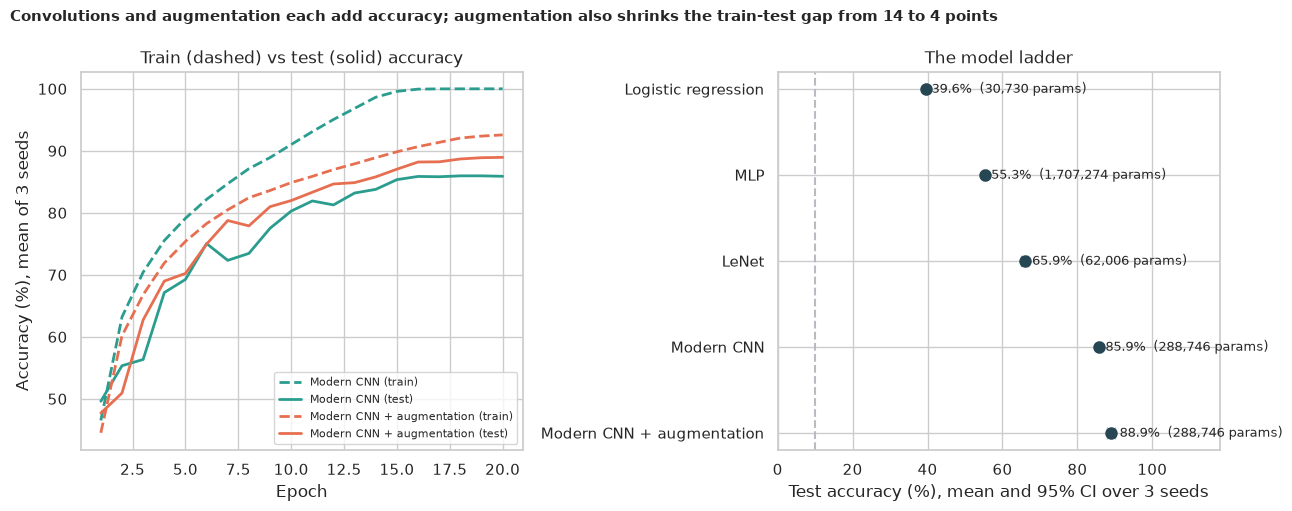

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
colours = {
    "Logistic regression": GREY,
    "MLP": PURPLE,
    "LeNet": NAVY,
    "Modern CNN": TEAL,
    "Modern CNN + augmentation": ORANGE,
}
epochs = np.arange(1, EPOCHS + 1)
for label in ("Modern CNN", "Modern CNN + augmentation"):
    for split, style in (("train", "--"), ("test", "-")):
        mean = np.mean([r["history"][split] for r in results[label]], axis=0) * 100
        axes[0].plot(epochs, mean, style, color=colours[label], lw=2, label=f"{label} ({split})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%), mean of 3 seeds")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_title("Train (dashed) vs test (solid) accuracy")

positions = np.arange(len(LABELS))
axes[1].errorbar(
    ladder["test accuracy"] * 100,
    positions,
    xerr=[
        (ladder["test accuracy"] - ladder["ci_low"]) * 100,
        (ladder["ci_high"] - ladder["test accuracy"]) * 100,
    ],
    fmt="o",
    color=NAVY,
    ecolor=GREY,
    capsize=4,
    markersize=8,
)
for position, label in enumerate(LABELS):
    accuracy = ladder.loc[label, "test accuracy"] * 100
    params = ladder.loc[label, "parameters"]
    axes[1].text(
        ladder.loc[label, "ci_high"] * 100 + 1.2,
        position,
        f"{accuracy:.1f}%  ({params:,} params)",
        va="center",
        fontsize=9,
    )
axes[1].axvline(10, color=GREY, ls="--")
axes[1].set_yticks(positions, LABELS)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 118)
axes[1].set_xlabel("Test accuracy (%), mean and 95% CI over 3 seeds")
axes[1].set_title("The model ladder")
gap = (
    ladder.loc["Modern CNN", "generalisation gap"],
    ladder.loc["Modern CNN + augmentation", "generalisation gap"],
)
fig.suptitle(
    f"Convolutions and augmentation each add accuracy; augmentation also shrinks the "
    f"train-test gap from {gap[0] * 100:.0f} to {gap[1] * 100:.0f} points",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_model_ladder.png", dpi=150)
plt.show()

## 8. H5: where do the mistakes go?

*What:* even the best model isn't perfect, and it is not equally good at everything. We take the **best model (the Modern CNN with augmentation)** and look at its 10,000 test predictions class by class: a **confusion matrix** (rows = the true class, columns = what the model said) and the per-class accuracy with **Wilson 95% confidence intervals** (a well-behaved CI for a proportion). **H₀:** the model is equally accurate on all ten classes, tested with a **chi-square test of homogeneity** of the correct/incorrect counts, with **Cramér's V** as the effect size (0 = no difference between classes, 1 = completely different).

In [11]:
best = "Modern CNN + augmentation"
predictions = results[best][0]["predictions"]
confusion = pd.crosstab(pd.Series(truth, name="true"), pd.Series(predictions, name="predicted"))
confusion.index, confusion.columns = CLASSES, CLASSES
normalised = confusion.div(confusion.sum(axis=1), axis=0)

per_class = pd.DataFrame(
    {
        "correct": np.diag(confusion.to_numpy()),
        "images": confusion.sum(axis=1).to_numpy(),
    },
    index=CLASSES,
)
per_class["accuracy"] = per_class["correct"] / per_class["images"]
per_class["ci_low"], per_class["ci_high"] = proportion_confint(
    per_class["correct"], per_class["images"], method="wilson"
)
chi2, p_classes, dof, _ = stats.chi2_contingency(
    np.column_stack([per_class["correct"], per_class["images"] - per_class["correct"]])
)
v = float(np.sqrt(chi2 / per_class["images"].sum()))
off = normalised.to_numpy().copy()
np.fill_diagonal(off, 0)
worst = np.unravel_index(off.argmax(), off.shape)
print(f"Overall accuracy of {best}: {per_class['correct'].sum() / per_class['images'].sum():.4f}")
print(
    f"Do classes differ in accuracy? chi2({dof}) = {chi2:.0f}, p = {fmt_p(p_classes)}, "
    f"Cramer's V = {v:.2f}"
)
print(
    f"Most common mix-up: true {CLASSES[worst[0]]} predicted as {CLASSES[worst[1]]} "
    f"({off[worst]:.1%} of {CLASSES[worst[0]]}s)"
)
per_class.sort_values("accuracy").style.format(
    {"accuracy": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"}
)

Overall accuracy of Modern CNN + augmentation: 0.8933
Do classes differ in accuracy? chi2(9) = 320, p = 1.5e-63, Cramer's V = 0.18
Most common mix-up: true cat predicted as dog (9.1% of cats)


,correct,images,accuracy,ci_low,ci_high
cat,769,1000,76.9%,74.2%,79.4%
dog,836,1000,83.6%,81.2%,85.8%
bird,848,1000,84.8%,82.4%,86.9%
deer,901,1000,90.1%,88.1%,91.8%
horse,911,1000,91.1%,89.2%,92.7%
plane,913,1000,91.3%,89.4%,92.9%
frog,924,1000,92.4%,90.6%,93.9%
truck,931,1000,93.1%,91.4%,94.5%
ship,941,1000,94.1%,92.5%,95.4%
car,959,1000,95.9%,94.5%,97.0%


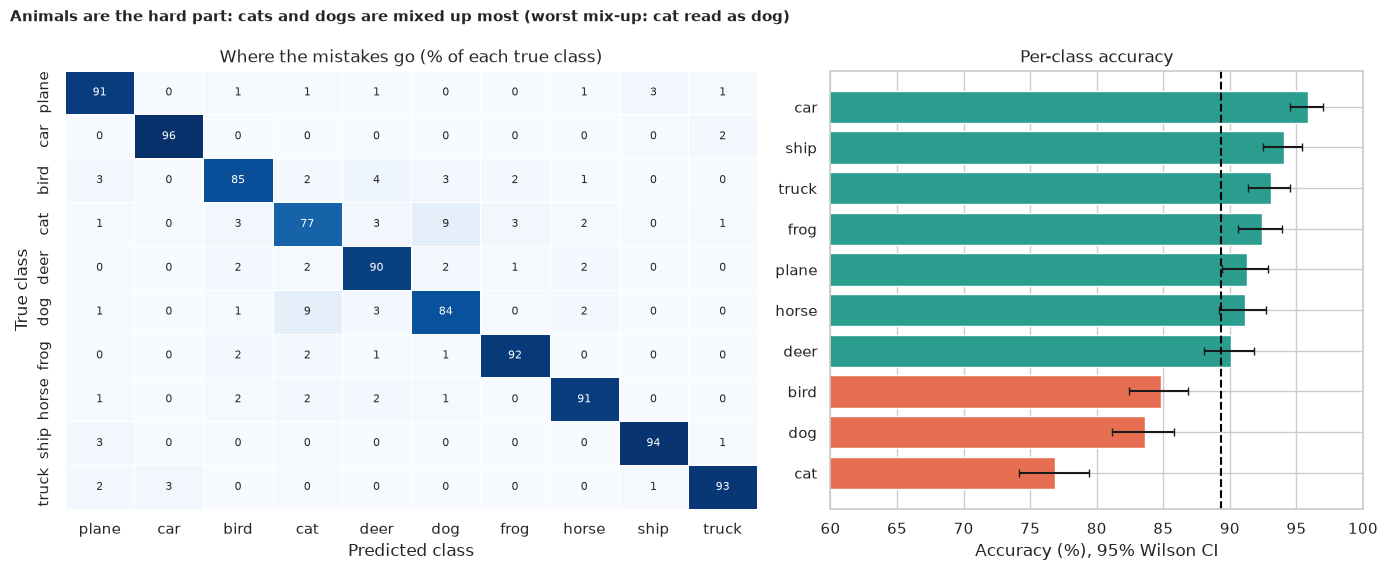

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(
    normalised * 100,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    linewidths=0.4,
    annot_kws={"fontsize": 8},
)
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("True class")
axes[0].set_title("Where the mistakes go (% of each true class)")

ordered = per_class.sort_values("accuracy")
ypos = np.arange(len(ordered))
bar_colours = [ORANGE if a < ordered["accuracy"].mean() else TEAL for a in ordered["accuracy"]]
axes[1].barh(
    ypos,
    ordered["accuracy"] * 100,
    color=bar_colours,
    xerr=[
        (ordered["accuracy"] - ordered["ci_low"]) * 100,
        (ordered["ci_high"] - ordered["accuracy"]) * 100,
    ],
    capsize=3,
)
axes[1].axvline(ordered["accuracy"].mean() * 100, color="black", ls="--")
axes[1].set_yticks(ypos, ordered.index)
axes[1].set_xlim(60, 100)
axes[1].set_xlabel("Accuracy (%), 95% Wilson CI")
axes[1].set_title("Per-class accuracy")
fig.suptitle(
    f"Animals are the hard part: {ordered.index[0]}s and {ordered.index[1]}s are mixed "
    f"up most (worst mix-up: {CLASSES[worst[0]]} read as {CLASSES[worst[1]]})",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_confusion.png", dpi=150)
plt.show()

**How to read this.** The best model gets **89.3%** of the 10,000 test images right on this seed, but not evenly:

- **The chi-square test rejects H₀** (χ²(9) ≈ 320, p ≈ 2e-63, Cramér's V ≈ 0.18, a small-to-medium effect): the classes really do differ in difficulty.
- **Easiest: vehicles.** Cars (95.9%), ships (94.1%) and trucks (93.1%), with tight CIs that sit well above the average (the dashed line). Vehicles have rigid, distinctive shapes.
- **Hardest: the animals.** **Cats are the worst at 76.9%** (95% CI 74.2% to 79.4%), then dogs (83.6%) and birds (84.8%). The CIs for cats and for cars do not overlap: that gap is real, not luck.
- **The most common mix-up is cat → dog:** **9.1% of cats are called dogs**, and the heat-map shows dogs and cats confused in *both* directions, plus a smaller cat-versus-bird and deer-versus-horse confusion. At 32 x 32 pixels, a fluffy four-legged animal on a sofa or lawn genuinely looks alike; many of these errors would trip up a person too.

## 9. 🎯 Takeaways

1. **Convolutions are about shape, not size.** An MLP with 1.7 million weights is 10.5 points *worse* than a 62,000-weight LeNet (McNemar p ≈ 8e-78), because convolutions share small filters across the whole image.
2. **The ladder is steep:** logistic regression about 40%, MLP about 55%, LeNet about 66%, a modern CNN about 86%, plus augmentation about 89%. Each step is large, consistent across seeds and significant on the shared test images.
3. **Augmentation is nearly free accuracy:** +3.6 points (CI +3.0 to +4.2) with no new data, and it shrinks the memorisation gap from 14 points to 4.
4. **Colour alone carries a lot of signal** (Kruskal-Wallis ε² ≈ 0.29), which is a warning as well as a convenience: a model can look smart by learning backgrounds.
5. **Accuracy hides uneven difficulty.** Cats are 77% accurate and cars 96% (Cramér's V ≈ 0.18); cats and dogs are the main confusion (9% of cats read as dogs).
6. **Compare models on the same test images.** McNemar's test, using only the images where two models disagree, gives a far sharper verdict than comparing the averages of three seeds.

## 10. ⚠️ Limitations and edge cases

- **Three seeds.** Seed-to-seed variation is small here, but three is few, and the CIs on the seed means are correspondingly wide in principle. The McNemar tests use one seed's predictions on 10,000 images.
- **One recipe for every model.** All models share one optimiser, schedule and 20 epochs. A model-specific search (especially for the MLP and LeNet) could narrow some gaps a little, though not close a 20-point one.
- **Modest training budget.** 20 epochs is short; deeper networks such as ResNets reach 93 to 95% on CIFAR-10 with longer training and more tricks (mixup, cutout, bigger widths).
- **The test set is used for the learning curves.** We plot test accuracy by epoch for illustration, but never used it to pick the epoch, the learning rate or the architecture, so the final numbers are not tuned to it. A separate validation split would be the strictest design.
- **Tiny images.** 32 x 32 pixels limits what any model can see, which caps accuracy on animals especially.
- **Pre-defined classes and a single dataset.** CIFAR-10's ten classes are tidy; real photos include unseen objects and very different lighting, and performance would drop.
- **Association, not understanding.** The network classifies patterns it has seen; it does not "know" what a cat is, and it can be fooled by backgrounds and tiny perturbations.

---
*Run `uv run jupyter nbconvert --to html --execute DL/cifar10-cnn/cifar10_cnn.ipynb --output-dir docs --output dl-cifar10-cnn` to rebuild the web version (`docs/dl-cifar10-cnn.html`).*